In [1]:
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

In [2]:
sample = "BII_S9" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Computing I(q): 100%|██████████████████████| 1000/1000 [00:04<00:00, 204.44it/s]


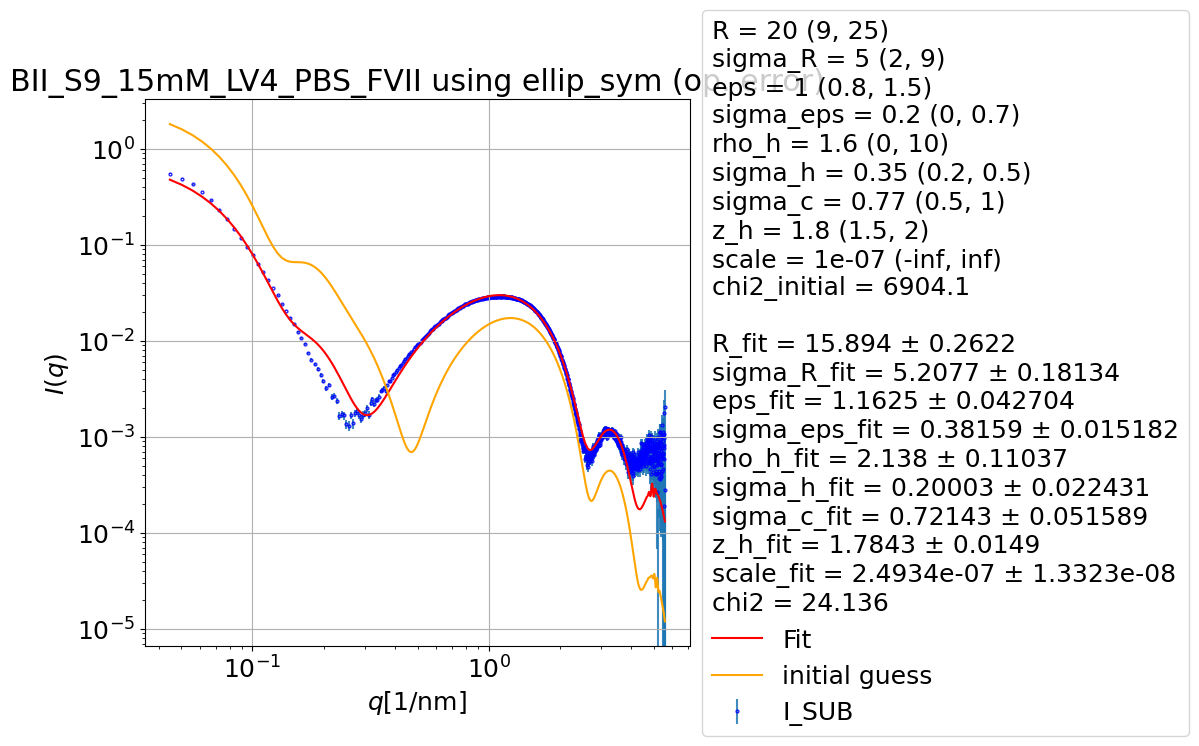

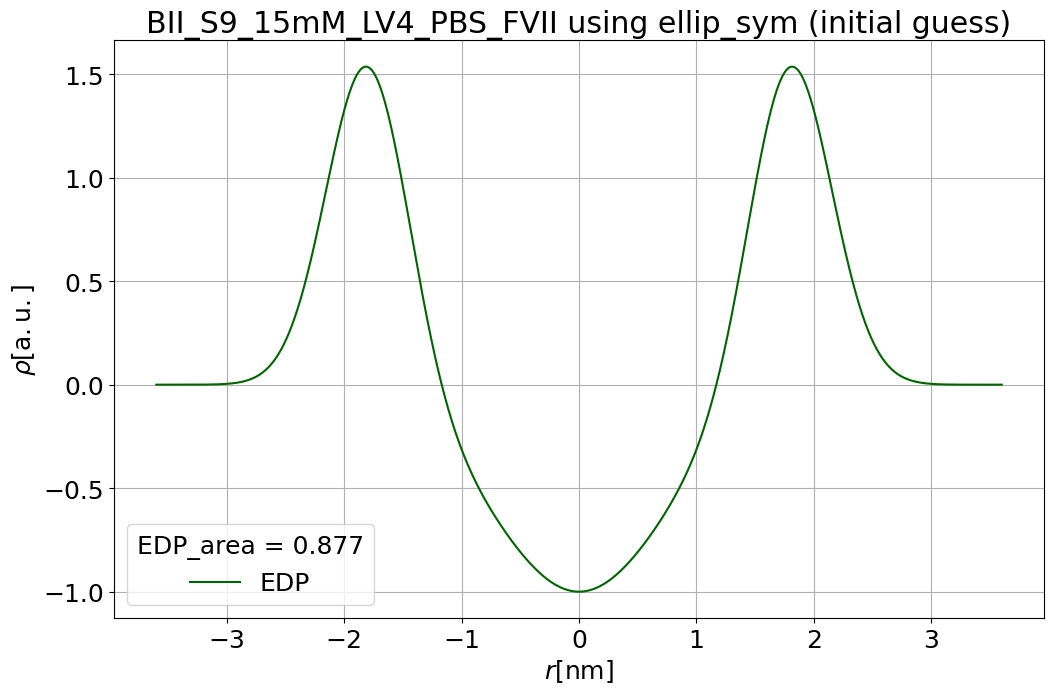

In [3]:
# ellipsoidal sym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid(q, R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
thinning = 4
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
R = 20
sigma_R = 5
eps = 1
sigma_eps = 0.2
rho_h = 1.6
sigma_h = 0.35
sigma_c = 0.77
z_h = 1.8
scale = 1e-7
c2 = 0
c3 = 0
c4 = 0.007

# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h_fit, sigma_h_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,      0,     0.2,        0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,     10,     0.5,          1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = q
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellip_sym (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h_fit, sigma_h_fit, sigma_c_fit, rho_h_fit, rho_h_fit, z_h_fit, z_h_fit, info_text, 
#              f'{sample} fac={fac} using {fit_function.__name__}')
fig=fit.EDP_plot(R, sigma_h, sigma_h, sigma_c, rho_h, rho_h, z_h, z_h, info_text, 
             f'{BM29.sample_dict[sample]} using ellip_sym (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


Computing I(q): 100%|██████████████████████| 1000/1000 [00:06<00:00, 144.90it/s]


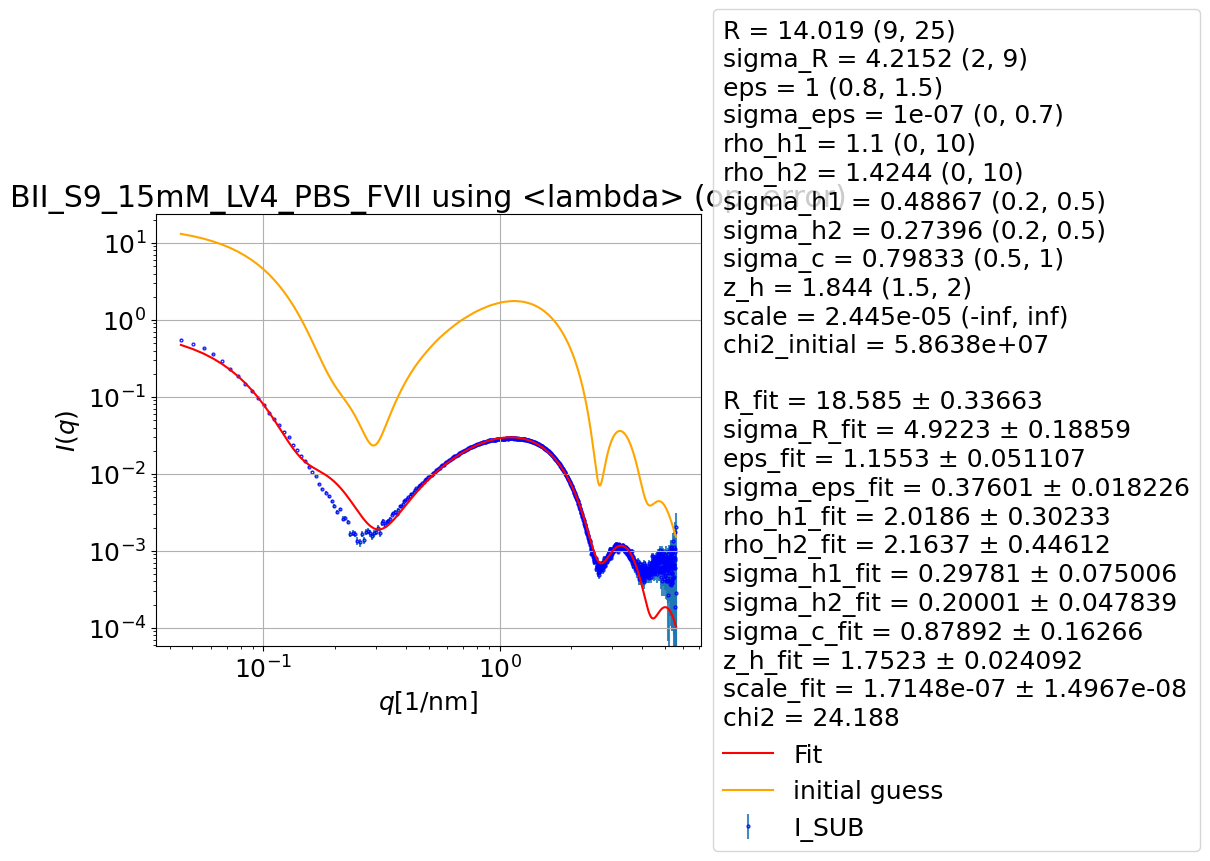

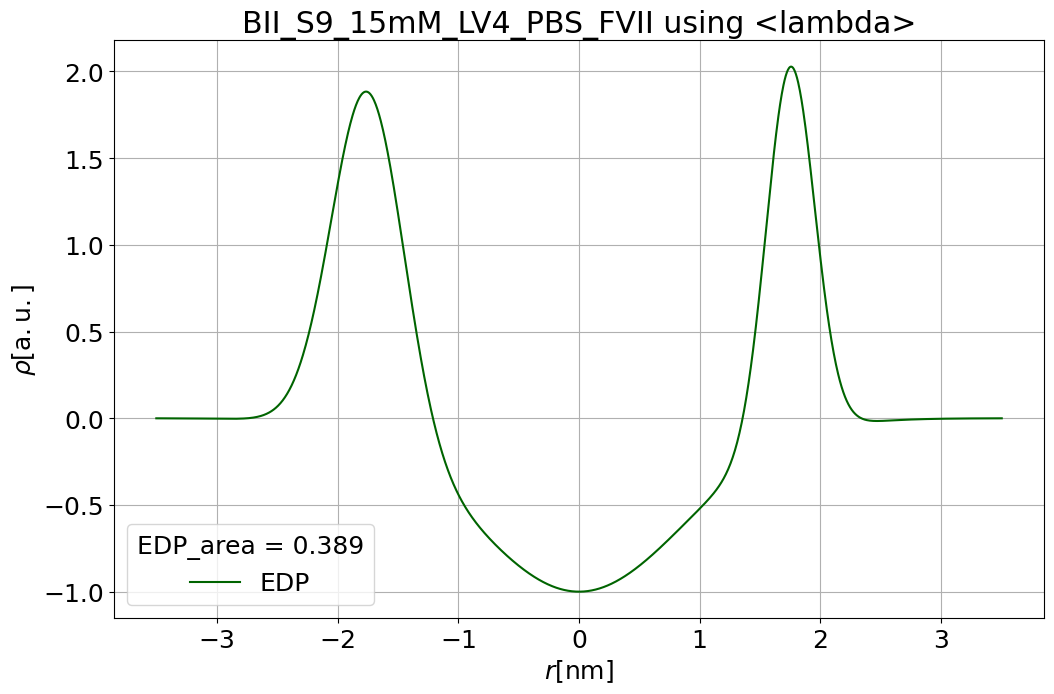

In [4]:
# ellipsoidal asym NO BGR
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
R       = 14.019
sigma_R = 4.2152
eps  = 1
sigma_eps = 0.0000001

rho_h1   = 1.1
rho_h2   = 1.4244
sigma_h1 = 0.48867
sigma_h2 = 0.27396
sigma_c = 0.79833
z_h = 1.844

scale = 0.00002445 
c2    = 0.002
c3    = 0.010452
c4    = 0

# ======================================================================
R_fit = 9.9997 
sigma_R_fit = 5.9694
eps_fit = 1.1317 
sigma_eps_fit = 0.10304 
rho_h1_fit = 1.8799 
rho_h2_fit = 1.0389 
sigma_h1_fit = 0.30377 
sigma_h2_fit = 0.44115 
sigma_c_fit = 0.89864 
z_h_fit = 1.7498 
# scale_fit = 0.0001882 
# c2_fit = 0
# c3_fit = 0 
# c4_fit = 0.079313 + 0.1786
scale_fit = 6.27710549513136e-06
c2_fit = 0
c3_fit = 0
c4_fit = 0.008600995613288826
chi2 = 8.0953

info_text_print = """ R = 14.019 (9, 25)
sigma_R = 4.2152 (2, 9)
eps = 1 (0.8, 1.5)
sigma_eps = 1e-07 (0, 0.7)
rho_h1 = 1.1 (0, 10)
rho_h2 = 1.4244 (0, 10)
sigma_h1 = 0.48867 (0.2, 0.5)
sigma_h2 = 0.27396 (0.2, 0.5)
sigma_c = 0.79833 (0.5, 1)
z_h = 1.844 (1.5, 2)
scale = 0.0001445 (-inf, inf)
c2 = 0.2 (0, 0.2)
c3 = 0.010452 (0, 0.5)
c4 = 0 (-inf, inf)
chi2_initial = 30.602
 
R_fit = 9.9997 ± 6.0109
sigma_R_fit = 5.9694 ± 1.4188
eps_fit = 1.1317 ± 0.81352
sigma_eps_fit = 0.10304 ± 0.44864
rho_h1_fit = 1.8799 ± 1.0905
rho_h2_fit = 1.0389 ± 0.6218
sigma_h1_fit = 0.30377 ± 0.38644
sigma_h2_fit = 0.44115 ± 0.27172
sigma_c_fit = 0.89864 ± 0.78094
z_h_fit = 1.7498 ± 0.28729
scale_fit = 6.2771-06
c2_fit = 0
c3_fit = 0
c4_fit = 0.0086
chi2 = 
"""
# ========================== Setting Bounds ==============================
#popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h1_fit, rho_h2_fit,   sigma_h1_fit, sigma_h2_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
#residuals = I - fit_function(q, *popt)
#chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
#print(chi2)
#residuals = I - fit_function(q, *popt)
#chi2 = np.sum((residuals / I_err_op)**2) / (len(I) - len(p0) - 1)
#print("chi2 op. err. /30", chi2)
#residuals = I - fit_function(q, *popt)
#chi2 = np.sum((residuals / I_err_op20)**2) / (len(I) - len(p0) - 1)
#print("chi2 op. err. /20", chi2)
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
             f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)